In [2]:
%run ../Preprocessing/Preprocessing.ipynb

Time Taken:  0.010156393051147461


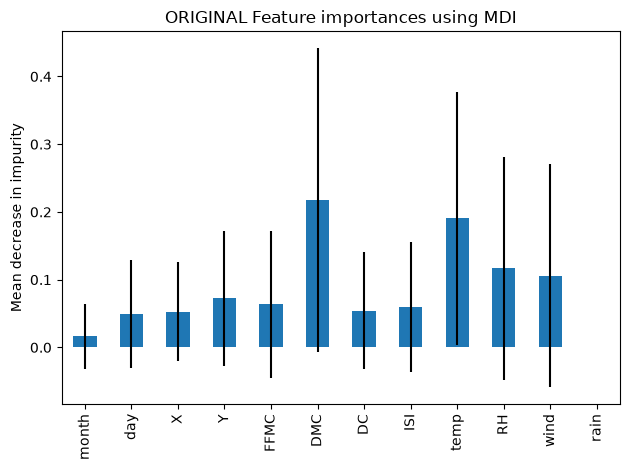

AttributeError: 'Pipeline' object has no attribute 'explained_variance_ratio_'

<Figure size 800x400 with 0 Axes>

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA

#Split the data
X = df[categorical_columns + numerical_columns]
y = df["area"]

forest = RandomForestRegressor(max_depth=20, random_state=RANDOM_STATE)



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

for title, preprocessing in preprocessing_pipelines.items():
    model = make_pipeline(preprocessing, forest)
    model.fit(X_train, y_train)
    
    start_time = time.time()
    importances = forest.feature_importances_
    std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
    elapsed_time = time.time() - start_time

    forest_importances = pd.Series(importances, index=pipeline_features[title])

    print("Time Taken: ", elapsed_time)
    
    fig, ax = plt.subplots()
    forest_importances.plot.bar(yerr=std, ax=ax)
    ax.set_title(title + " Feature importances using MDI")
    ax.set_ylabel("Mean decrease in impurity")
    fig.tight_layout()
    plt.show()
    